# Smart City housing: exploratory data analysis (EDA)

**Goal:** find out what real OpenStreetMap (OSM) data exists for residential buildings, so the RAG material for the
capacity estimate (`HOUSING_CAPACITY` in the LLM API) is built from facts instead of guesses.

**Flow:** 1 load the data (and check it is not cut off) · 2 data quality · 3 distributions · 4 relationships ·
5 information tiers · 6 capacity baseline from floor area · 7 export RAG material.

**What the first run showed:** OSM almost never has `building:flats` (0%) and rarely `height` (1%). It does have the footprint
(100%, computed from the geometry) and the number of levels (64%). The baseline therefore works from **floor area**
(footprint x levels) and converts it to residents with figures from Danmarks Statistik (listed in the configuration cell).

**Important:** there is no real capacity in OSM. *Baseline capacity* is a documented rule, not ground truth.

## 0. Configuration

In [33]:
from pathlib import Path
import hashlib, json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (8, 4)

# --- data -------------------------------------------------------------------------------------------------
DATA_CSV = Path("data/housing_dataset.csv")
RAW_JSON = Path("data/overpass_raw.json")
DOWNLOAD_IF_MISSING = True            # download when the CSV does not exist (delete the CSV to download again)
BBOX = (55.66, 12.55, 55.70, 12.62)   # south, west, north, east (Smart City default: central Copenhagen)
TILES = 3                             # the box is split into TILES x TILES requests so the limit does not cut it off
LIMIT_PER_TILE = 3000
CHECK_COUNT = False                   # True: ask Overpass how many buildings the box holds (one light request)

# --- reference figures (sources: see the table in section 6) ----------------------------------------------
# Average dwelling size (m2) and persons per dwelling by dwelling type. Used to turn floor area into residents.
APARTMENT_DWELLING_M2 = 84.5   # etageboliger, Copenhagen city, 2026 (Statistikbanken BOL106, via Bolius)
DETACHED_DWELLING_M2 = 155.3   # parcelhuse/stuehuse, 2026 (BOL106, via Bolius)
TERRACED_DWELLING_M2 = 93.0    # raekke-/kaede-/dobbelthuse, 1 Jan 2016 (Danmarks Statistik Nyt nr. 164)
PERSONS_PER_DWELLING = {"apartment": 1.8, "detached": 2.6, "terraced": 1.9}   # 1 Jan 2020 (Danmarks Statistik Nyt)
LEGAL_M2_PER_PERSON = 20.0     # used only as an upper bound, see section 6.1

# --- assumptions (NOT sourced: change and watch the sensitivity table) ------------------------------------
FLOOR_EFFICIENCY = 0.80        # share of footprint x levels that is dwelling area (walls, stairs, shops are not)
ROOF_LEVEL_WEIGHT = 0.0        # how much a roof level (roof:levels) counts as a floor: 0 = not at all, 1 = fully
M_PER_LEVEL = 3.0              # storey height, used to turn a height into levels when levels are missing

# --- plausibility limits for cleaning ---------------------------------------------------------------------
MAX_LEVELS, MAX_HEIGHT_M, MAX_FLATS = 60, 200, 500
MIN_FOOTPRINT_M2, MAX_FOOTPRINT_M2 = 10, 20000

# --- RAG export ---------------------------------------------------------------------------------------------
MIN_N = 30               # a derived figure needs at least this many buildings behind it
EVAL_SHARE = 0.30        # share of buildings kept out of the RAG examples, for testing
EXAMPLES_PER_GROUP = 5   # RAG examples per (dwelling group, confidence)
INCLUDE_FOOTPRINT_IN_EXAMPLES = True
RANDOM_SEED = 42
OUT_DIR = Path("rag_export")

## 1. Load the data

If the CSV does not exist yet, the next cell downloads it with `build_housing_dataset.py` (same folder), tile by tile.
Overpass is a shared public service: the download runs only when the file is missing, and the raw response is saved.
Finished tiles are saved in `data/tiles/`, so if Overpass fails halfway, run the cell again and only the missing tiles are fetched.
To download again from scratch (for example with other tiles), delete `data/housing_dataset.csv` and the `data/tiles/` folder.

In [34]:
if not DATA_CSV.exists():
    if not DOWNLOAD_IF_MISSING:
        raise FileNotFoundError(f"{DATA_CSV} not found. Run build_housing_dataset.py first.")
    import importlib, build_housing_dataset as bhd
    importlib.reload(bhd)   # pick up a replaced script without restarting the kernel
    response = bhd.fetch_tiled(bhd.DEFAULT_URL, BBOX, LIMIT_PER_TILE, TILES, cache_dir="data/tiles")
    RAW_JSON.parent.mkdir(parents=True, exist_ok=True)
    RAW_JSON.write_text(json.dumps(response), encoding="utf-8")
    bhd.write_csv(bhd.rows_from_response(response), str(DATA_CSV))

df = pd.read_csv(DATA_CSV)
for col in ["levels", "flats", "height_m", "roof_levels", "footprint_m2"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
print(df.shape)
df.head()

Tile 1/9: downloaded
Tile 2/9: downloaded
Tile 3/9: downloaded
Tile 4/9: downloaded
https://overpass-api.de/api/interpreter: HTTP Error 502: Bad Gateway. Waiting 15s (try 1/4) ...
Tile 5/9: downloaded
https://overpass-api.de/api/interpreter: HTTP Error 502: Bad Gateway. Waiting 15s (try 1/4) ...
Tile 6/9: downloaded
Tile 7/9: downloaded
https://overpass-api.de/api/interpreter: HTTP Error 502: Bad Gateway. Waiting 15s (try 1/4) ...
Tile 8/9: downloaded
https://overpass-api.de/api/interpreter: HTTP Error 502: Bad Gateway. Waiting 15s (try 1/4) ...


(2175, 15)


Tile 9/9: downloaded


,osm_type,osm_id,building,housing_type,levels,flats,height_m,roof_levels,footprint_m2,node_count,lat,lon,name,street_address,tags_json
0,way,25520727,apartments,apartment,NaN,NaN,NaN,NaN,652.0,4,55.663144,12.571224,Pressesiloen,NaN,"{""building"": ""apartments"", ""name"": ""Pressesilo..."
1,way,26659669,apartments,apartment,5.0,NaN,NaN,1.0,379.5,13,55.671830,12.554274,NaN,NaN,"{""building"": ""apartments"", ""building:levels"": ..."
2,way,26659675,apartments,apartment,5.0,NaN,NaN,1.0,408.6,17,55.672212,12.554480,NaN,NaN,"{""building"": ""apartments"", ""building:levels"": ..."
3,way,26659690,apartments,apartment,5.0,NaN,NaN,1.0,714.4,31,55.671636,12.554964,NaN,NaN,"{""building"": ""apartments"", ""building:levels"": ..."
4,way,27113489,apartments,apartment,15.0,NaN,NaN,NaN,1158.4,12,55.661991,12.569703,Wennbergsiloen,NaN,"{""building"": ""apartments"", ""building:levels"": ..."


### 1.1 Is the sample complete or cut off?

The first run asked for at most 2,000 buildings and got exactly 2,000, so it was probably cut off, and Overpass returns
buildings in id order, which is not a random sample. The cell below compares the number of rows with the limit
and, if `CHECK_COUNT = True`, with the number of buildings the box really holds.

In [35]:
print("rows in the CSV:", len(df), "| capacity of the download:", LIMIT_PER_TILE * TILES * TILES)
if CHECK_COUNT:
    import importlib, build_housing_dataset as bhd
    importlib.reload(bhd)
    total = bhd.count_buildings(bhd.DEFAULT_URL, BBOX)
    print("building ways in the box:", total, "| share downloaded:", f"{len(df) / total:.0%}")
    if len(df) < total:
        print("The sample is cut off. Raise TILES or LIMIT_PER_TILE, delete the CSV and run again.")
elif len(df) >= LIMIT_PER_TILE * TILES * TILES:
    print("The download hit its limit: raise TILES or LIMIT_PER_TILE.")

rows in the CSV: 2175 | capacity of the download: 27000


In [36]:
df.dtypes

osm_type              str
osm_id              int64
building              str
housing_type          str
levels            float64
flats             float64
height_m          float64
roof_levels       float64
footprint_m2      float64
node_count          int64
lat               float64
lon               float64
name                  str
street_address    float64
tags_json             str
dtype: object

## 2. Data quality

### 2.1 Which building types are in the data?

,buildings,share_pct
building,,
apartments,2033,93.5
terrace,50,2.3
semidetached_house,29,1.3
house,19,0.9
detached,19,0.9
dormitory,14,0.6
residential,11,0.5


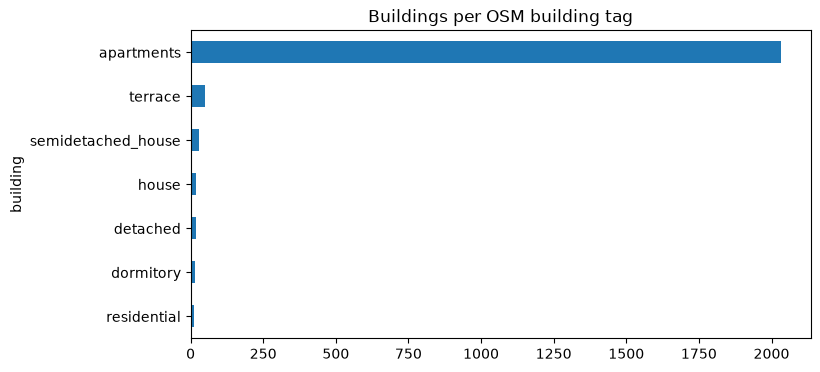

In [37]:
types = df["building"].value_counts()
display(types.to_frame("buildings").assign(share_pct=(types / len(df) * 100).round(1)))
types.plot.barh(title="Buildings per OSM building tag").invert_yaxis()
plt.show()

### 2.2 How often is each field filled?

This table is the most important result for the RAG design: it shows which kinds of rules the data can support.

In [38]:
FIELDS = ["levels", "flats", "height_m", "roof_levels", "footprint_m2", "street_address", "name"]
coverage = df[FIELDS].notna().mean().mul(100).round(1).rename("filled_pct")
display(coverage.to_frame())
by_type = df.groupby("housing_type")[FIELDS].agg(lambda s: round(s.notna().mean() * 100, 1))
by_type.insert(0, "n", df.groupby("housing_type").size())
display(by_type)
by_building = df.groupby("building")[FIELDS].agg(lambda s: round(s.notna().mean() * 100, 1))
by_building.insert(0, "n", df.groupby("building").size())
display(by_building.sort_values("n", ascending=False))

,filled_pct
levels,64.6
flats,0.1
height_m,1.1
roof_levels,52.8
footprint_m2,100.0
street_address,0.0
name,3.0


,n,levels,flats,height_m,roof_levels,footprint_m2,street_address,name
housing_type,,,,,,,,
apartment,2058,64.7,0.1,1.2,52.9,100.0,0.0,2.6
house,117,62.4,0.0,0.0,50.4,100.0,0.0,9.4


,n,levels,flats,height_m,roof_levels,footprint_m2,street_address,name
building,,,,,,,,
apartments,2033,64.6,0.1,1.2,53.2,100.0,0.0,2.1
terrace,50,84.0,0.0,0.0,66.0,100.0,0.0,4.0
semidetached_house,29,55.2,0.0,0.0,51.7,100.0,0.0,0.0
house,19,42.1,0.0,0.0,26.3,100.0,0.0,47.4
detached,19,36.8,0.0,0.0,31.6,100.0,0.0,0.0
dormitory,14,71.4,0.0,0.0,35.7,100.0,0.0,71.4
residential,11,72.7,0.0,0.0,27.3,100.0,0.0,18.2


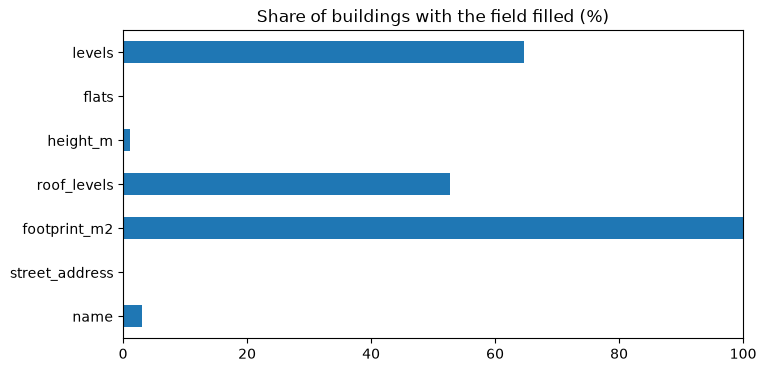

In [39]:
coverage.plot.barh(title="Share of buildings with the field filled (%)", xlim=(0, 100)).invert_yaxis()
plt.show()

### 2.3 Duplicates and implausible values

In [40]:
print("duplicate (osm_type, osm_id):", df.duplicated(["osm_type", "osm_id"]).sum())
checks = {
    f"levels outside 1..{MAX_LEVELS}": ~df["levels"].between(1, MAX_LEVELS) & df["levels"].notna(),
    f"height_m outside 1..{MAX_HEIGHT_M}": ~df["height_m"].between(1, MAX_HEIGHT_M) & df["height_m"].notna(),
    f"flats outside 1..{MAX_FLATS}": ~df["flats"].between(1, MAX_FLATS) & df["flats"].notna(),
    f"footprint outside {MIN_FOOTPRINT_M2}..{MAX_FOOTPRINT_M2} m2": ~df["footprint_m2"].between(MIN_FOOTPRINT_M2, MAX_FOOTPRINT_M2) & df["footprint_m2"].notna(),
}
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="rows").to_frame()

duplicate (osm_type, osm_id): 0


,rows
levels outside 1..60,0
height_m outside 1..200,0
flats outside 1..500,0
footprint outside 10..20000 m2,5


Implausible values are set to missing in new `*_clean` columns. The raw columns are kept.

In [41]:
df["levels_clean"] = df["levels"].where(df["levels"].between(1, MAX_LEVELS))
df["height_clean"] = df["height_m"].where(df["height_m"].between(1, MAX_HEIGHT_M))
df["flats_clean"] = df["flats"].where(df["flats"].between(1, MAX_FLATS))
df["footprint_clean"] = df["footprint_m2"].where(df["footprint_m2"].between(MIN_FOOTPRINT_M2, MAX_FOOTPRINT_M2))
df[["levels_clean", "height_clean", "flats_clean", "footprint_clean"]].describe().round(1)

,levels_clean,height_clean,flats_clean,footprint_clean
count,1405.0,24.0,3.0,2170.0
mean,4.5,21.5,74.0,481.4
std,1.5,16.7,53.8,551.4
min,1.0,10.0,12.0,10.8
25%,4.0,14.0,57.0,183.6
50%,5.0,15.0,102.0,307.2
75%,5.0,22.0,105.0,539.1
max,24.0,80.0,108.0,6613.4


### 2.4 Dwelling groups

Smart City only has `house` and `apartment`, but the OSM tags are finer, and the reference statistics are per
dwelling type. The first run showed that `terrace` buildings are not single houses (one has a 2,078 m2 footprint), and
`dormitory` capacity is a number of rooms, not flats. A separate **dwelling group** is therefore used for the baseline:

| Group | OSM `building` values | Dwellings in the building |
|---|---|---|
| apartment | `apartments`, `residential` | floor area / average apartment size |
| detached | `house`, `detached` | 1 |
| terraced | `terrace`, `semidetached_house` | floor area / average terraced-house size |
| dormitory | `dormitory` | no baseline (capacity is rooms) |

In [42]:
GROUPS = {"apartments": "apartment", "residential": "apartment", "house": "detached", "detached": "detached",
          "terrace": "terraced", "semidetached_house": "terraced", "dormitory": "dormitory"}
df["dwelling_group"] = df["building"].map(GROUPS).fillna("apartment")
df["dwelling_group"].value_counts().to_frame("buildings")

,buildings
dwelling_group,
apartment,2044
terraced,79
detached,38
dormitory,14


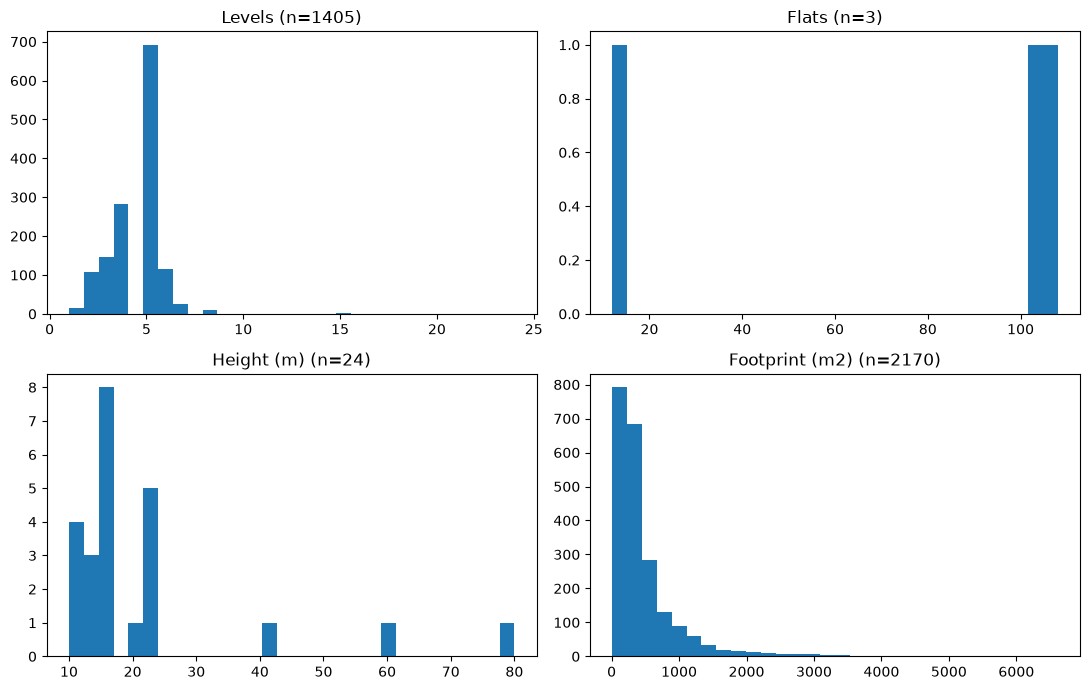

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (col, title) in zip(axes.ravel(), [("levels_clean", "Levels"), ("flats_clean", "Flats"),
                                           ("height_clean", "Height (m)"), ("footprint_clean", "Footprint (m2)")]):
    data = df[col].dropna()
    if len(data):
        ax.hist(data, bins=30)
    ax.set_title(f"{title} (n={len(data)})")
plt.tight_layout()
plt.show()

In [44]:
df.groupby("housing_type")[["levels_clean", "flats_clean", "height_clean", "footprint_clean"]].describe().round(1).T

housing_type           apartment   house
levels_clean    count     1332.0    73.0
                mean         4.6     2.2
                std          1.4     0.6
                min          1.0     1.0
                25%          4.0     2.0
                50%          5.0     2.0
                75%          5.0     3.0
                max         24.0     3.0
flats_clean     count        3.0     0.0
                mean        74.0     NaN
                std         53.8     NaN
                min         12.0     NaN
                25%         57.0     NaN
                50%        102.0     NaN
                75%        105.0     NaN
                max        108.0     NaN
height_clean    count       24.0     0.0
                mean        21.5     NaN
                std         16.7     NaN
                min         10.0     NaN
                25%         14.0     NaN
                50%         15.0     NaN
                75%         22.0     NaN
                max         80.0     NaN
footprint_clean count     2055.0   115.0
                mean       493.8   259.4
                std        557.2   370.0
                min         10.8    18.1
                25%        190.4    71.4
                50%        317.0   144.3
                75%        551.6   261.2
                max       6613.4  2077.9

## 4. Relationships between fields

Each relationship below is a candidate **rule** for the RAG material, for example "metres per level" or
"flats per level". A rule is only used if enough buildings support it (`MIN_N`).

### 4.1 Height and levels

buildings with both: 14


,m_per_level
count,14.00
mean,3.90
std,0.88
min,3.00
25%,3.08
50%,3.64
75%,4.40
max,5.62


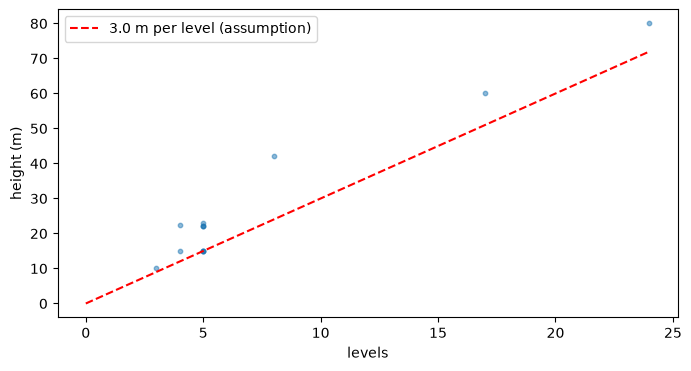

In [45]:
both = df.dropna(subset=["height_clean", "levels_clean"]).copy()
both["m_per_level"] = both["height_clean"] / both["levels_clean"]
print("buildings with both:", len(both))
if len(both):
    display(both["m_per_level"].describe().round(2).to_frame())
    plt.scatter(both["levels_clean"], both["height_clean"], s=10, alpha=0.5)
    xs = np.array([0, both["levels_clean"].max()])
    plt.plot(xs, xs * M_PER_LEVEL, "r--", label=f"{M_PER_LEVEL} m per level (assumption)")
    plt.xlabel("levels"); plt.ylabel("height (m)"); plt.legend(); plt.show()

### 4.2 Flats (almost never tagged)

`building:flats` is the field the first rules were built on. The cell shows how few buildings have it.

In [46]:
flat_data = df.dropna(subset=["flats_clean"])
print("buildings with flats:", len(flat_data), "of", len(df))
flat_data[["osm_id", "building", "levels_clean", "footprint_clean", "flats_clean"]].head(20)

buildings with flats: 3 of 2175


,osm_id,building,levels_clean,footprint_clean,flats_clean
1088,823046940,apartments,6.0,950.3,102.0
1396,106898499,apartments,5.0,1725.2,108.0
2106,823043622,apartments,5.0,178.6,12.0


### 4.3 Floor area

Gross floor area = footprint x number of levels. A building without levels gets the median number of levels of its
dwelling group, and is marked as *imputed* so the answer can carry a lower confidence.

In [47]:
df["levels_eff"] = df["levels_clean"].fillna((df["height_clean"] / M_PER_LEVEL).round())
df.loc[df["levels_eff"] < 1, "levels_eff"] = np.nan
median_levels = df.groupby("dwelling_group")["levels_eff"].median()
print("median levels per dwelling group (used when levels are missing):")
print(median_levels.to_string())
df["levels_imputed"] = df["levels_eff"].isna()
df["levels_used"] = df["levels_eff"].fillna(df["dwelling_group"].map(median_levels))
df["floors_used"] = df["levels_used"] + ROOF_LEVEL_WEIGHT * df["roof_levels"].fillna(0)
df["gross_floor_area"] = df["footprint_clean"] * df["floors_used"]
df["usable_area"] = df["gross_floor_area"] * FLOOR_EFFICIENCY
print("buildings without a floor area:", int(df["gross_floor_area"].isna().sum()))
df.groupby("dwelling_group")[["footprint_clean", "levels_used", "gross_floor_area"]].describe().round(0).T

median levels per dwelling group (used when levels are missing):
dwelling_group
apartment    5.0
detached     1.0
dormitory    3.5
terraced     2.0
buildings without a floor area: 5


dwelling_group          apartment  detached  dormitory  terraced
footprint_clean  count     2041.0      36.0       14.0      79.0
                 mean       492.0     152.0      744.0     308.0
                 std        556.0     132.0      704.0     430.0
                 min         11.0      18.0      179.0      45.0
                 25%        190.0      77.0      199.0      62.0
                 50%        317.0     118.0      419.0     166.0
                 75%        551.0     171.0     1104.0     304.0
                 max       6613.0     691.0     2147.0    2078.0
levels_used      count     2044.0      38.0       14.0      79.0
                 mean         5.0       1.0        4.0       2.0
                 std          1.0       0.0        2.0       0.0
                 min          1.0       1.0        3.0       1.0
                 25%          5.0       1.0        3.0       2.0
                 50%          5.0       1.0        4.0       2.0
                 75%          5.0       1.0        4.0       3.0
                 max         24.0       3.0        9.0       3.0
gross_floor_area count     2041.0      36.0       14.0      79.0
                 mean      2431.0     195.0     3502.0     666.0
                 std       3116.0     192.0     4181.0     855.0
                 min         11.0      18.0      537.0      90.0
                 25%        884.0      77.0      659.0     125.0
                 50%       1526.0     138.0     1424.0     378.0
                 75%       2642.0     217.0     4040.0     639.0
                 max      52907.0     848.0    14263.0    4156.0

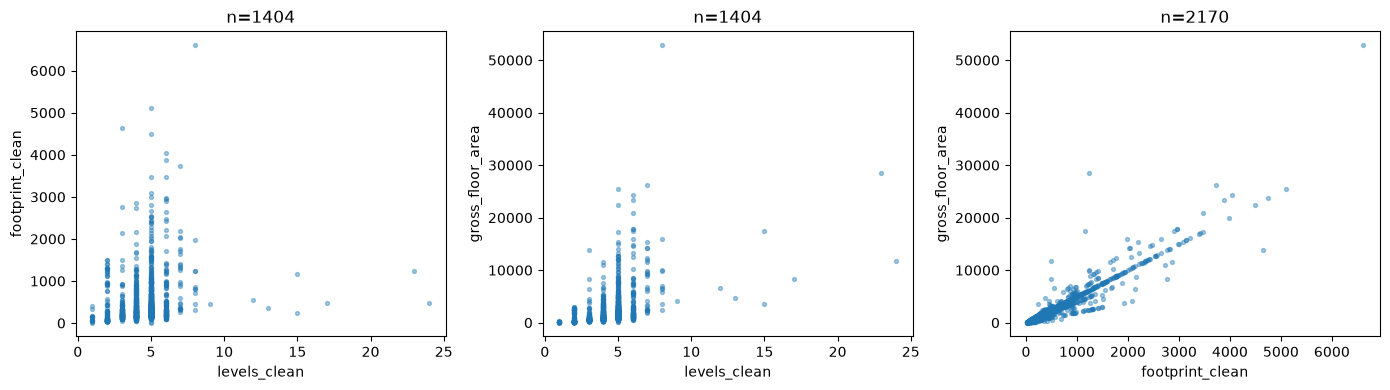

,levels_clean,height_clean,footprint_clean,roof_levels
levels_clean,1.00,0.70,0.30,-0.25
height_clean,0.70,1.00,0.28,0.43
footprint_clean,0.30,0.28,1.00,-0.13
roof_levels,-0.25,0.43,-0.13,1.00


In [48]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (x, y) in zip(axes, [("levels_clean", "footprint_clean"), ("levels_clean", "gross_floor_area"), ("footprint_clean", "gross_floor_area")]):
    d = df.dropna(subset=[x, y])
    ax.scatter(d[x], d[y], s=8, alpha=0.4); ax.set_xlabel(x); ax.set_ylabel(y); ax.set_title(f"n={len(d)}")
plt.tight_layout(); plt.show()
df[["levels_clean", "height_clean", "footprint_clean", "roof_levels"]].corr(method="spearman").round(2)

### 4.4 Roof levels

`roof:levels` is filled for about half of the buildings in the first run. It counts attic or roof storeys, which
may or may not hold dwellings. The cell shows how it relates to `building:levels`. `ROOF_LEVEL_WEIGHT` in the
configuration decides whether roof levels count as floors (default: no); change it and see the effect on the totals below.

roof:levels filled: 1148 of 2175


roof_levels,0,1,2,missing
levels_clean,,,,
1,3,6,1,5
2,13,91,2,3
3,15,97,6,28
4,20,224,8,31
5,89,470,7,126
6,51,30,0,35
7,8,2,0,16
8,3,0,0,7
9,0,0,0,1


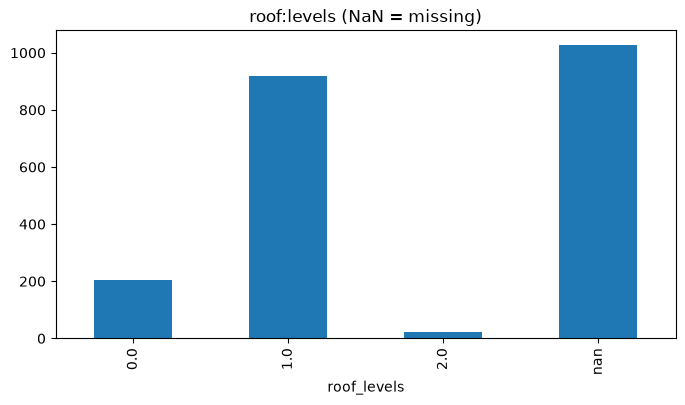

In [49]:
print("roof:levels filled:", int(df["roof_levels"].notna().sum()), "of", len(df))
display(pd.crosstab(df["levels_clean"].fillna(-1).astype(int).replace(-1, "missing"), df["roof_levels"].fillna(-1).astype(int).replace(-1, "missing")))
df["roof_levels"].value_counts(dropna=False).sort_index().plot.bar(title="roof:levels (NaN = missing)")
plt.show()

## 5. How much information does each building have? (tiers)

The LLM sees one building at a time, so what matters is **which combination of fields** a building has. The tier
decides which estimation rule applies and how confident the answer can be.

| Tier | Meaning | Confidence |
|---|---|---|
| A | number of flats known | high |
| B | levels (or height) and footprint known | medium |
| C | levels (or height) known, no footprint | low |
| D | footprint only (levels imputed) | low |
| E | nothing but the building type | none |

In [50]:
def tier(row):
    if pd.notna(row["flats_clean"]):
        return "A"
    if pd.notna(row["levels_eff"]) and pd.notna(row["footprint_clean"]):
        return "B"
    if pd.notna(row["levels_eff"]):
        return "C"
    if pd.notna(row["footprint_clean"]):
        return "D"
    return "E"

df["tier"] = df.apply(tier, axis=1)
display(pd.crosstab(df["tier"], df["dwelling_group"], margins=True))
(pd.crosstab(df["tier"], df["dwelling_group"], normalize="columns") * 100).round(1)

dwelling_group,apartment,detached,dormitory,terraced,All
tier,,,,,
A,3,0,0,0,3
B,1328,15,10,58,1411
C,1,0,0,0,1
D,710,21,4,21,756
E,2,2,0,0,4
All,2044,38,14,79,2175


dwelling_group,apartment,detached,dormitory,terraced
tier,,,,
A,0.1,0.0,0.0,0.0
B,65.0,39.5,71.4,73.4
C,0.0,0.0,0.0,0.0
D,34.7,55.3,28.6,26.6
E,0.1,5.3,0.0,0.0


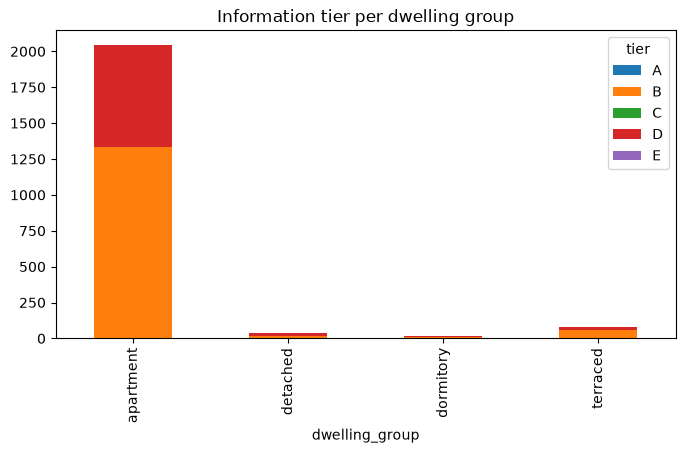

In [51]:
pd.crosstab(df["dwelling_group"], df["tier"]).plot.bar(stacked=True, title="Information tier per dwelling group")
plt.show()

## 6. Capacity baseline from floor area (a rule, not ground truth)

**Capacity means the number of citizens Smart City may place in the building.** The baseline gives each building a
*transparent* estimate and records **why**. It is used for RAG examples that show the reasoning and as a comparison point
for the LLM. It must **not** be presented as the true capacity.

For apartment and terraced buildings:

1. `usable area = footprint x floors x FLOOR_EFFICIENCY`
2. `dwellings = usable area / average dwelling size` (or the flat count when it is known)
3. `capacity = dwellings x persons per dwelling`
4. capacity is capped at `usable area / 20 m2` (see 6.1), and is at least 1.

A detached house is one dwelling. Dormitories get no baseline.

### 6.1 Sources and legal context

**Reference figures used (statistics, not rules):**

| Figure | Value | Source |
|---|---|---|
| Average apartment size, Copenhagen city | 84.5 m2 (2026) | Statistikbanken BOL106, quoted by [Bolius](https://www.bolius.dk/danskerne-faar-mere-og-mere-plads-i-boligen-36883) |
| Average detached house size | 155.3 m2 (2026) | same |
| Average terraced/semi-detached house size | 93 m2 (1 Jan 2016) | [Danmarks Statistik, Nyt nr. 164](https://www.dst.dk/nyt/21543) |
| Persons per dwelling: apartments / detached / terraced | 1.8 / 2.6 / 1.9 (1 Jan 2020) | [Danmarks Statistik, "Lidt flere end to personer pr. bolig"](https://www.dst.dk/nyt/30704) |
| Average floor area per person, Denmark | 53.9 m2 (2026) | [Danmarks Statistik, Personer i boliger](https://www.dst.dk/da/Statistik/emner/borgere/boligforhold/personer-i-boliger) |
| Floor area per person, Copenhagen municipality | about 40 m2 (1 Jan 2016) | [Danmarks Statistik, Nyt nr. 164](https://www.dst.dk/nyt/21543) |

The Bolius figures are secondary (Bolius cites Statistikbanken); check BOL106 itself before the synopsis. The 2016 and 2020
figures are older than the rest.

**Legal limits (upper bounds, not typical occupancy).** I read these on summary sites, not on retsinformation.dk, and I am not a lawyer:

- Rental housing: at most **2 persons per habitable room** (`beboelsesrum`), [Lov om boligforhold § 14](https://www.lovguiden.dk/loven/lov-om-boligforhold/14,15,17) (earlier [Boligreguleringsloven § 52 a](https://danskelove.dk/boligreguleringsloven/52a)).
- The municipality may allow more if the dwelling has **at least 20 m2 per person** after the increase (§ 15).
- The family-reunification housing requirement uses the same two tests: at most two persons per room, or at least 20 m2 per person ([nyidanmark.dk](https://nyidanmark.dk/en-GB/Words-and-concepts/US/Familie/Family-reunification---Independent-reasonably-sized-residence)).
- The building regulations (BR18, chapter 9) govern layout but, in the guidance I could read, set no occupancy limit.

OSM has no room count, so the per-room limit cannot be applied. The 20 m2 per person figure is the only area-based bound, so it is
used as a **ceiling** on the capacity, not as the estimate. Real occupancy is much lower (about 40-54 m2 per person).

count  median   min    max
dwelling_group confidence                            
apartment      high            3   184.0  22.0  194.0
               low           710    25.0   2.0  405.0
               medium       1328    27.0   1.0  902.0
               none            0     NaN   NaN    NaN
detached       low            21     3.0   1.0    3.0
               medium         15     3.0   1.0    3.0
               none            0     NaN   NaN    NaN
dormitory      none            0     NaN   NaN    NaN
terraced       low            21     6.0   4.0   68.0
               medium         58     7.0   2.0   49.0

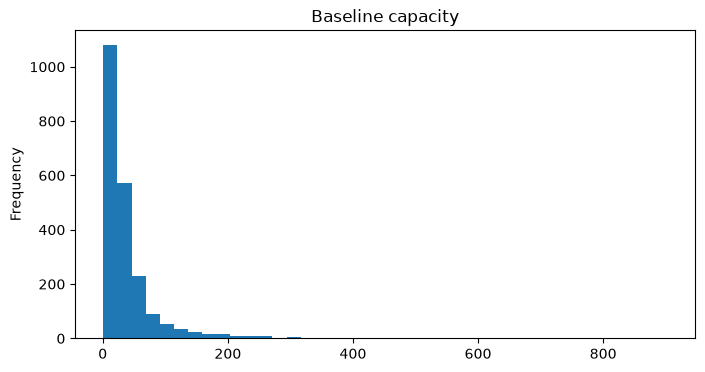

buildings without baseline: 19 of 2175


In [52]:
def baseline(row):
    """Returns (capacity, basis, confidence) or (None, 'no basis', 'none')."""
    group = row["dwelling_group"]
    if group == "dormitory":
        return None, "dormitory: capacity is rooms, not flats; no baseline", "none"
    persons = PERSONS_PER_DWELLING[group]
    imputed = bool(row["levels_imputed"])
    usable = row["usable_area"]
    if pd.notna(row["flats_clean"]):
        dwellings = int(row["flats_clean"])
        basis = f"{dwellings} flats x {persons:g} persons per dwelling"
        confidence = "high"
        raw = dwellings * persons
        ceiling = None
    else:
        if pd.isna(usable):
            return None, "no footprint: no floor area", "none"
        floors = row["floors_used"]
        area_text = (f"footprint {row['footprint_clean']:.0f} m2 x {floors:g} floors"
                     f"{' (levels missing, median of the group used)' if imputed else ''} x {FLOOR_EFFICIENCY:g} = {usable:.0f} m2 usable")
        if group == "detached":
            dwellings, size = 1, DETACHED_DWELLING_M2
            basis = f"{area_text}; one dwelling x {persons:g} persons"
        else:
            size = APARTMENT_DWELLING_M2 if group == "apartment" else TERRACED_DWELLING_M2
            dwellings = max(1, round(usable / size))
            basis = f"{area_text}; / {size:g} m2 per dwelling = {dwellings} dwellings x {persons:g} persons"
        confidence = "low" if imputed else "medium"
        raw = dwellings * persons
        ceiling = max(1, int(usable // LEGAL_M2_PER_PERSON))
    capacity = max(1, round(raw))
    if ceiling is not None and capacity > ceiling:
        capacity = ceiling
        basis += f"; limited to {ceiling} by the 20 m2 per person ceiling"
    return capacity, basis, confidence

result = df.apply(baseline, axis=1, result_type="expand")
df["baseline_capacity"], df["baseline_basis"], df["confidence"] = result[0], result[1], result[2]
display(df.groupby(["dwelling_group", "confidence"])["baseline_capacity"].agg(["count", "median", "min", "max"]))
df["baseline_capacity"].dropna().plot.hist(bins=40, title="Baseline capacity")
plt.show()
print("buildings without baseline:", int(df["baseline_capacity"].isna().sum()), "of", len(df))

### 6.2 Sensitivity to the assumption

`FLOOR_EFFICIENCY` is not sourced. The table recomputes the total and the median capacity for apartment and terraced
buildings with other values, so you can see how much the assumption matters.

In [53]:
rows = []
saved = FLOOR_EFFICIENCY
for eff in [0.6, 0.7, 0.8, 0.9, 1.0]:
    d = df.copy()
    d["usable_area"] = d["gross_floor_area"] * eff
    FLOOR_EFFICIENCY = eff
    out = d.apply(baseline, axis=1, result_type="expand")
    cap = out[0].dropna()
    rows.append({"floor_efficiency": eff, "buildings": len(cap), "total_capacity": int(cap.sum()), "median": float(cap.median())})
FLOOR_EFFICIENCY = saved
pd.DataFrame(rows)

,floor_efficiency,buildings,total_capacity,median
0,0.6,2156,64378,18.0
1,0.7,2156,75041,22.0
2,0.8,2156,85708,23.0
3,0.9,2156,96358,27.0
4,1.0,2156,106930,31.0


## 7. Export material for the RAG pipeline

Four files are written to `rag_export/`:

| File | Content | Use |
|---|---|---|
| `housing-profile.md` | what the dataset looks like, how often fields are missing | RAG source |
| `housing-rules.md` | figures from the data, sourced reference figures, legal limits, which rule to use | RAG source |
| `housing-examples.md` | example buildings with reasoning, one `##` section each | RAG source (retrieved by similarity) |
| `eval_set.csv` | buildings **not** used as examples, with an empty `capacity_label` column | hand-label about 40-60 rows, then use for testing |

The LLM API splits its knowledge file on `## ` headings, so every section below becomes one retrievable chunk.

In [54]:
OUT_DIR.mkdir(exist_ok=True)

def share(seed, osm_id):
    digest = hashlib.md5(f"{seed}-{osm_id}".encode()).hexdigest()
    return int(digest[:8], 16) / 16 ** 8

df["is_eval"] = df["osm_id"].map(lambda i: share(RANDOM_SEED, i) < EVAL_SHARE)
pool, evalset = df[~df["is_eval"]], df[df["is_eval"]]
print("example pool:", len(pool), "| held-out evaluation set:", len(evalset))

example pool: 1528 | held-out evaluation set: 647


In [55]:
def pct(x):
    return f"{x:.0f}%"

n = len(df)
lines = ["## Dataset profile: residential buildings from OpenStreetMap", "",
         f"Source: OpenStreetMap via the Overpass API, residential `building=*` ways, {n} buildings, "
         f"bounding box south={BBOX[0]}, west={BBOX[1]}, north={BBOX[2]}, east={BBOX[3]}. "
         "OSM is volunteer-maintained and may be outdated.", ""]
lines += ["Building types: " + ", ".join(f"{k} {pct(v / n * 100)}" for k, v in df["building"].value_counts().items()) + ".", ""]
lines += ["## How complete the data is", "",
          "Share of buildings where the field is filled in. A missing value is not zero.", ""]
for field, label in [("levels_clean", "building:levels (number of floors)"), ("flats_clean", "building:flats (number of dwellings)"),
                     ("height_clean", "height"), ("roof_levels", "roof:levels"), ("footprint_clean", "footprint area (computed from the geometry)")]:
    parts = ", ".join(f"{t} {pct(g[field].notna().mean() * 100)}" for t, g in df.groupby("dwelling_group"))
    lines.append(f"- {label}: {pct(df[field].notna().mean() * 100)} overall ({parts}).")
lines += ["", "The number of dwellings (`building:flats`) is almost never available, so the number of flats is usually unknown. "
          "The estimate then has to come from the floor area (footprint x floors).", ""]
lines += ["Information tiers (share of buildings): " +
          ", ".join(f"{t} {pct(v / n * 100)}" for t, v in df["tier"].value_counts().sort_index().items()) +
          ". A = flats known, B = levels and footprint, C = levels only, D = footprint only, E = type only.", ""]
(OUT_DIR / "housing-profile.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))

## Dataset profile: residential buildings from OpenStreetMap

Source: OpenStreetMap via the Overpass API, residential `building=*` ways, 2175 buildings, bounding box south=55.66, west=12.55, north=55.7, east=12.62. OSM is volunteer-maintained and may be outdated.

Building types: apartments 93%, terrace 2%, semidetached_house 1%, house 1%, detached 1%, dormitory 1%, residential 1%.

## How complete the data is

Share of buildings where the field is filled in. A missing value is not zero.

- building:levels (number of floors): 65% overall (apartment 65%, detached 39%, dormitory 71%, terraced 73%).
- building:flats (number of dwellings): 0% overall (apartment 0%, detached 0%, dormitory 0%, terraced 0%).
- height: 1% overall (apartment 1%, detached 0%, dormitory 0%, terraced 0%).
- roof:levels: 53% overall (apartment 53%, detached 29%, dormitory 36%, terraced 61%).
- footprint area (computed from the geometry): 100% overall (apartment 100%, detached 95%, dormitory 100%, terraced 100%).

T

In [56]:
def stat_line(label, series, unit):
    s = series.dropna()
    if len(s) < MIN_N:
        return f"- {label}: not enough buildings in the data (n={len(s)}, need {MIN_N}); no figure derived."
    q1, med, q3 = s.quantile([0.25, 0.5, 0.75])
    return f"- {label}: median {med:.0f} {unit} (middle half {q1:.0f} to {q3:.0f}), from n={len(s)} buildings."

def group_lines(column, label, unit):
    out = []
    for g, part in df.groupby("dwelling_group"):
        out.append(stat_line(f"{label}, {g}", part[column], unit))
    return out

rules = ["## Figures from the OpenStreetMap data", "",
         "These figures describe the buildings in this dataset (central Copenhagen). They are not statistics about the whole country.", ""]
rules += group_lines("footprint_clean", "Footprint", "m2")
rules += group_lines("levels_clean", "Number of floors", "floors")
rules += ["", "## Reference figures from Danmarks Statistik", "",
          f"- Average apartment size, Copenhagen city: {APARTMENT_DWELLING_M2:g} m2 (2026, Statistikbanken BOL106, quoted by Bolius).",
          f"- Average detached house size: {DETACHED_DWELLING_M2:g} m2 (2026, BOL106, quoted by Bolius).",
          f"- Average terraced or semi-detached house size: {TERRACED_DWELLING_M2:g} m2 (1 January 2016, Danmarks Statistik Nyt nr. 164, https://www.dst.dk/nyt/21543).",
          f"- Persons per dwelling in 2020: apartments {PERSONS_PER_DWELLING['apartment']:g}, detached houses {PERSONS_PER_DWELLING['detached']:g}, "
          f"terraced and semi-detached houses {PERSONS_PER_DWELLING['terraced']:g} (https://www.dst.dk/nyt/30704).",
          "- Average floor area per person in Denmark: 53.9 m2 in 2026 (https://www.dst.dk/da/Statistik/emner/borgere/boligforhold/personer-i-boliger). "
          "For Copenhagen municipality about 40 m2 in 2016.", "",
          "## Legal limits (upper bounds, not typical occupancy)", "",
          "- Rental housing: at most 2 persons per habitable room (Lov om boligforhold, paragraph 14).",
          "- The municipality may allow more if the dwelling has at least 20 m2 per person (paragraph 15). The same two tests are used for the family reunification housing requirement.",
          "- The number of rooms is not available in OpenStreetMap, so only the 20 m2 per person limit can be applied. It is used as a ceiling, never as the estimate.", "",
          "## Assumptions used for capacity (not sourced)", "",
          f"- Share of footprint x floors that is dwelling area: {FLOOR_EFFICIENCY:g} (walls, stairs and shops are not dwelling area).",
          f"- Roof levels count as {ROOF_LEVEL_WEIGHT:g} of a floor.",
          f"- A height is turned into floors with {M_PER_LEVEL:g} m per floor when the number of floors is missing; when both are missing the median of the building group is used and the confidence is low.",
          "- There is no real capacity data. Estimates are reasoned from the building, not measured.", "",
          "## Which rule to use", "",
          "1. Number of flats known: capacity = flats x persons per dwelling for the building type, confidence high.",
          "2. Apartment or terraced building with footprint and floors: usable area = footprint x floors x share; dwellings = usable area / average dwelling size; capacity = dwellings x persons per dwelling; confidence medium.",
          "3. Detached house: one dwelling, capacity = persons per dwelling for detached houses (floor area only limits it).",
          "4. Floors missing: use the median number of floors of the building type and say so; confidence low.",
          "5. Always limit the capacity to usable area / 20 m2, and never return less than 1.",
          "6. Dormitories: capacity is rooms, not flats; say that no reliable estimate is possible.",
          "7. Nothing but the type known: give a conservative estimate, confidence low, and say that the data is missing.", ""]
(OUT_DIR / "housing-rules.md").write_text("\n".join(rules), encoding="utf-8")
print("\n".join(rules))

## Figures from the OpenStreetMap data

These figures describe the buildings in this dataset (central Copenhagen). They are not statistics about the whole country.

- Footprint, apartment: median 317 m2 (middle half 190 to 551), from n=2041 buildings.
- Footprint, detached: median 118 m2 (middle half 77 to 171), from n=36 buildings.
- Footprint, dormitory: not enough buildings in the data (n=14, need 30); no figure derived.
- Footprint, terraced: median 166 m2 (middle half 62 to 304), from n=79 buildings.
- Number of floors, apartment: median 5 floors (middle half 4 to 5), from n=1322 buildings.
- Number of floors, detached: not enough buildings in the data (n=15, need 30); no figure derived.
- Number of floors, dormitory: not enough buildings in the data (n=10, need 30); no figure derived.
- Number of floors, terraced: median 2 floors (middle half 2 to 3), from n=58 buildings.

## Reference figures from Danmarks Statistik

- Average apartment size, Copenhagen city: 84.5 m2 (2026, Stat

In [57]:
def fmt(value, integer=False):
    if pd.isna(value):
        return "unknown"
    return str(int(round(value))) if integer else f"{value:g}"

parts = []
candidates = pool.dropna(subset=["baseline_capacity"])
for (g, c), part in candidates.groupby(["dwelling_group", "confidence"]):
    parts.append(part.sample(min(len(part), EXAMPLES_PER_GROUP), random_state=RANDOM_SEED))
examples = pd.concat(parts).sort_values(["dwelling_group", "confidence"]) if parts else candidates.iloc[0:0]

blocks = ["# Worked examples: buildings with a reasoned capacity", "",
          "Capacities below come from the rules in this material, not from measurements. They show how to reason from the data.", ""]
for i, (_, r) in enumerate(examples.iterrows(), 1):
    block = [f"## Example {i}: {r['dwelling_group']}, confidence {r['confidence']}",
             f"housingType: {r['housing_type']}",
             f"buildingType: {r['building']}",
             f"numberOfLevels: {fmt(r['levels_clean'], True)}",
             f"numberOfFlats: {fmt(r['flats_clean'], True)}",
             f"heightMeters: {fmt(r['height_clean'])}"]
    if INCLUDE_FOOTPRINT_IN_EXAMPLES:
        block.append(f"footprintM2: {fmt(r['footprint_clean'], True)}")
    block.append(f"Reasoning: {r['baseline_basis']}.")
    block.append(f"capacity: {int(r['baseline_capacity'])}")
    block.append(f"confidence: {r['confidence']}")
    blocks += block + [""]
(OUT_DIR / "housing-examples.md").write_text("\n".join(blocks), encoding="utf-8")

eval_cols = ["osm_type", "osm_id", "building", "dwelling_group", "tier", "levels_clean", "flats_clean", "height_clean",
             "roof_levels", "footprint_clean", "baseline_capacity", "confidence", "baseline_basis"]
evalset[eval_cols].assign(capacity_label="").to_csv(OUT_DIR / "eval_set.csv", index=False)
print(len(examples), "examples written; eval_set.csv has", len(evalset), "rows")
print("\n".join(blocks[:34]))

31 examples written; eval_set.csv has 647 rows
# Worked examples: buildings with a reasoned capacity

Capacities below come from the rules in this material, not from measurements. They show how to reason from the data.

## Example 1: apartment, confidence high
housingType: apartment
buildingType: apartments
numberOfLevels: 5
numberOfFlats: 12
heightMeters: unknown
footprintM2: 179
Reasoning: 12 flats x 1.8 persons per dwelling.
capacity: 22
confidence: high

## Example 2: apartment, confidence low
housingType: apartment
buildingType: apartments
numberOfLevels: unknown
numberOfFlats: unknown
heightMeters: unknown
footprintM2: 146
Reasoning: footprint 146 m2 x 5 floors (levels missing, median of the group used) x 0.8 = 583 m2 usable; / 84.5 m2 per dwelling = 7 dwellings x 1.8 persons.
capacity: 13
confidence: low

## Example 3: apartment, confidence low
housingType: apartment
buildingType: apartments
numberOfLevels: unknown
numberOfFlats: unknown
heightMeters: unknown
footprintM2: 158
Re

## 8. What this means for the next steps

Fill in after running the notebook on the real data:

- How many buildings does the box hold, and is the sample complete (section 1.1)?
- Which tiers are common? Tier D (levels imputed) means a low-confidence answer.
- Does `ROOF_LEVEL_WEIGHT` or `FLOOR_EFFICIENCY` change the totals much (section 6.2)? Those are the unsourced assumptions.
- `footprintM2` and `buildingType` are in the examples, but a `Housing` row has neither. The request builder would have to look
  them up from Overpass by OSM id, or the examples are exported without them (`INCLUDE_FOOTPRINT_IN_EXAMPLES = False`).
- Hand-label 40-60 rows of `eval_set.csv` before comparing the LLM, the regression and the baseline.